# Emometer: highlight emotion features per token (Neuronpedia)

For a short story (read from `data/stories/the-yellow-wallpaper.txt`), compute the activation of five emotion SAE features on every token and highlight each token in the colour of the emotion that fires on it.

- **Model:** `llama3.1-8b` (Llama 3.1 8B).
- **SAEs:** Llama Scope 32k residual-stream SAEs (`<layer>-llamascope-res-32k`). Each emotion feature lives in a different layer, so each is read from its own SAE.

A feature is *present* on a token when its activation is > 0. If several emotions fire on the same token, the token takes the colour of the one with the highest activation relative to that feature's max activation; hover a token to see all of them.

Neuronpedia's activation endpoint takes at most about 256 tokens per request, so the text is split into sentence-aligned chunks of about 900 characters. Each chunk is sent in its own request, several at a time. A chunk that keeps failing is split into smaller pieces and retried. The model sees each chunk on its own, so the activations at the start of a chunk don't take the earlier chunks into account.

Neuronpedia allows 1,000 activation requests per hour, and each chunk costs one request per emotion (5), so about 30,000 words fit in an hour; past that, the run pauses and carries on by itself. Every finished request is saved under `.activation_cache/`, so a long text that stops partway (rate limit, lost connection, closed laptop) resumes where it left off when you run it again, and re-running the same text costs no requests.

In [1]:
import contextlib
import hashlib
import html
import io
import json
import re
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from functools import cache
from pathlib import Path

import requests
from dotenv import load_dotenv
from IPython.display import HTML, display
from neuronpedia.requests.activation_request import ActivationRequest
from neuronpedia.requests.base_request import NPRateLimitError
from neuronpedia.requests.sae_feature_request import SAEFeatureRequest

load_dotenv()

MODEL_ID = "llama3.1-8b"

# emotion -> (SAE source, feature index, highlight colour)
EMOTIONS = {
    "joy":     ("24-llamascope-res-32k", 13054, "yellow"),
    "sadness": ("31-llamascope-res-32k", 4689,  "blue"),
    "anger":   ("30-llamascope-res-32k", 31298, "red"),
    "anxiety": ("26-llamascope-res-32k", 9593,  "orange"),
    "fear":    ("28-llamascope-res-32k", 29458, "purple"),
}
TEXT_ON = {"yellow": "black", "orange": "black"}  # all other colours get white text

# Neuronpedia's activation endpoint returns a 500 for texts over ~256 tokens (about 1,150 characters of
# prose), so the input is split into chunks that are each sent in a request of their own. 900 characters
# leaves room for text that tokenizes densely (dialect, names, numbers).
MAX_CHUNK_CHARS = 900
MIN_CHUNK_CHARS = 60     # don't split a failing chunk below this; give up instead
MAX_CONCURRENT = 8       # requests in flight at once
RETRIES = 4              # attempts per request on server errors before the chunk is split
TIMEOUT = 60             # seconds per request
# Neuronpedia allows 1,000 activation requests per hour per API key, and every chunk costs one request per
# emotion. When the limit is hit, all requests pause and then carry on; set WAIT_FOR_RATE_LIMIT = False to
# stop with an error instead (finished requests stay cached either way).
RATE_LIMIT_PER_HOUR = 1000
RATE_LIMIT_PAUSE = 300   # seconds
WAIT_FOR_RATE_LIMIT = True
CACHE_DIR = Path(".activation_cache")  # one JSON file per (feature, chunk) request


In [2]:
@contextlib.contextmanager
def _quiet():
    # Neuronpedia request classes print a status line per request. redirect_stdout is process-wide,
    # so only enter this from the main thread, around all the worker threads.
    with contextlib.redirect_stdout(io.StringIO()):
        yield


@cache
def feature_info(source: str, index: int) -> dict:
    """Autointerp label and approximate max activation for a feature."""
    with _quiet():
        data = json.loads(SAEFeatureRequest().get(MODEL_ID, source, str(index)).jsonData)
    explanations = data.get("explanations") or []
    label = explanations[0]["description"].strip() if explanations else "(no autointerp label)"
    return {"label": label, "max_act": data.get("maxActApprox") or 1.0}


def _chunks(text: str, max_chars: int = MAX_CHUNK_CHARS) -> list[tuple[str, str]]:
    """Split `text` into (chunk, following whitespace) pairs of at most ~max_chars, cutting after sentences."""
    parts = re.split(r"(\s+)", text.strip())
    words, seps = parts[0::2], parts[1::2] + [""]
    is_sentence_end = [bool(re.search(r"[.!?][\"'”’)\]]*$", w)) for w in words]

    chunks, start, length = [], 0, 0
    for i, word in enumerate(words):
        if length + len(word) > max_chars and i > start:
            ends = [j for j in range(start, i) if is_sentence_end[j]]
            cut = ends[-1] if ends else i - 1
            chunks.append(("".join(parts[2 * start : 2 * cut + 1]), seps[cut]))
            start = cut + 1
            length = len("".join(parts[2 * start : 2 * i]))
        length += len(word) + len(seps[i])
    chunks.append(("".join(parts[2 * start :]), ""))
    return chunks


class _ServerError(Exception):
    """Neuronpedia kept failing on a text (usually because it is too long)."""


def _cache_path(source: str, index: int, text: str) -> Path:
    key = hashlib.sha256(f"{MODEL_ID}|{source}|{index}|{text}".encode()).hexdigest()
    return CACHE_DIR / key[:2] / f"{key}.json"


_pause_lock = threading.Lock()
_paused_until = 0.0


def _wait_out_rate_limit(hit: bool = False) -> None:
    """Sleep while a rate-limit pause is on; `hit=True` starts one. All worker threads share the pause."""
    global _paused_until
    with _pause_lock:
        if hit and time.time() >= _paused_until:
            _paused_until = time.time() + RATE_LIMIT_PAUSE
            print(
                f"{time.strftime('%H:%M')} rate limited (Neuronpedia allows {RATE_LIMIT_PER_HOUR} activation requests "
                f"per hour); pausing {RATE_LIMIT_PAUSE // 60} min. Finished requests are cached.",
                file=sys.stderr,
            )
        wait = _paused_until - time.time()
    if wait > 0:
        time.sleep(wait)


def _request(source: str, index: int, text: str) -> tuple[list[str], list[float]]:
    """Tokens of `text` and one feature's activation on each, from the disk cache or from Neuronpedia."""
    path = _cache_path(source, index, text)
    if path.exists():
        data = json.loads(path.read_text())
        return data["tokens"], data["values"]

    payload = {"feature": {"modelId": MODEL_ID, "layer": source, "index": str(index)}, "customText": text}
    failures = 0
    while True:
        _wait_out_rate_limit()
        try:
            # send_request instead of compute_activation_for_text so the request can carry a timeout.
            result = ActivationRequest().send_request(method="POST", json=payload, uri="new", timeout=TIMEOUT)
            break
        except NPRateLimitError:
            # Being rate limited says nothing about the text, so wait it out instead of splitting the chunk.
            if not WAIT_FOR_RATE_LIMIT:
                raise
            _wait_out_rate_limit(hit=True)
            continue
        except requests.HTTPError as e:
            if "Server error" not in str(e):
                raise
        except (requests.ConnectionError, requests.Timeout):
            pass
        failures += 1
        if failures == RETRIES:
            raise _ServerError(text)
        time.sleep(2**failures)

    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(f".{threading.get_ident()}.tmp")
    tmp.write_text(json.dumps({"tokens": result["tokens"], "values": result["values"]}))
    tmp.replace(path)  # atomic, so an interrupted run never leaves a half-written cache file
    return result["tokens"], result["values"]


def _join(pieces: list[tuple[list[str], dict[str, list[float]]]], seps: list[str]):
    """Concatenate per-piece results, putting each piece's trailing whitespace back as a zero-activation token."""
    tokens, acts = [], {e: [] for e in EMOTIONS}
    for (piece_tokens, piece_acts), sep in zip(pieces, seps):
        tokens += piece_tokens + ([sep] if sep else [])
        for e in EMOTIONS:
            acts[e] += piece_acts[e] + ([0.0] if sep else [])
    return tokens, acts


def _chunk_activations(chunk: str) -> tuple[list[str], dict[str, list[float]]]:
    """Tokens of one chunk and every emotion's activations on them; splits the chunk if Neuronpedia keeps failing."""
    try:
        results = {e: _request(*EMOTIONS[e][:2], chunk) for e in EMOTIONS}
    except _ServerError:
        # All emotions must share one tokenization, so the whole chunk is re-split, not just the failing request.
        pieces = _chunks(chunk, len(chunk) // 2)
        if len(chunk) < 2 * MIN_CHUNK_CHARS or len(pieces) < 2:
            raise
        return _join([_chunk_activations(p) for p, _ in pieces], [s for _, s in pieces])

    tokens = next(iter(results.values()))[0]
    return tokens, {e: values for e, (_, values) in results.items()}


def emotion_activations(text: str) -> tuple[list[str], dict[str, list[float]]]:
    """Return the tokens of `text` and, for each emotion, its feature's activation on every token.

    Finished requests are cached on disk, so if a long run stops partway, running it again picks up where it left off.
    """
    chunks = _chunks(text)
    done, started, step = 0, time.time(), max(1, len(chunks) // 20)
    results = []
    # Progress goes to stderr, because _quiet() swallows stdout.
    with _quiet(), ThreadPoolExecutor(MAX_CONCURRENT) as pool:
        for result in pool.map(_chunk_activations, [c for c, _ in chunks]):
            results.append(result)
            done += 1
            if done % step == 0 or done == len(chunks):
                print(f"{done}/{len(chunks)} chunks, {time.time() - started:.0f}s", file=sys.stderr)
    return _join(results, [s for _, s in chunks])


def _style() -> str:
    rules = [".emo span { padding:1px 0; border-radius:3px; }"]
    for e, (_, _, color) in EMOTIONS.items():
        rules.append(f".emo .{e} {{ background:{color}; color:{TEXT_ON.get(color, 'white')}; }}")
    return f"<style>{' '.join(rules)}</style>"


def highlight(text: str) -> None:
    tokens, acts = emotion_activations(text)
    strength = {e: 1 / feature_info(*EMOTIONS[e][:2])["max_act"] for e in EMOTIONS}

    # Plain tokens are written as bare text and highlighted ones as <span class=...>, so the HTML for a
    # novel-length text stays small enough for Jupyter to render.
    pieces, counts = [], dict.fromkeys(EMOTIONS, 0)
    for pos, token in enumerate(tokens):
        present = {e: acts[e][pos] for e in EMOTIONS if acts[e][pos] > 0}
        if not present:
            pieces.append(html.escape(token))
            continue
        top = max(present, key=lambda e: present[e] * strength[e])
        counts[top] += 1
        title = html.escape("\n".join(f"{e}: {v:.2f}" for e, v in present.items()))
        pieces.append(f'<span class="{top}" title="{title}">{html.escape(token)}</span>')

    legend = []
    for e, (source, index, _) in EMOTIONS.items():
        label = html.escape(f"{source} #{index}: {feature_info(source, index)['label']}")
        legend.append(f'<span class="{e}" title="{label}"> {e} ({counts[e]}) </span>')
    legend = " ".join(legend)
    display(HTML(
        f'{_style()}<div class="emo">'
        f'<div style="font-size:0.85em; margin-bottom:0.5em;">{legend} &nbsp; tokens highlighted per emotion, out of {len(tokens)}</div>'
        f'<div style="font-size:1.2em; line-height:1.9em; max-width:50em; white-space:pre-wrap;">{"".join(pieces)}</div>'
        f"</div>"
    ))

In [3]:
story_path = Path("data/stories/the-yellow-wallpaper.txt")
story = story_path.read_text(encoding="utf-8")
n_requests = len(_chunks(story)) * len(EMOTIONS)
print(f"{len(story.split())} words, {n_requests} requests (cached ones are skipped), "
      f"at least {n_requests / RATE_LIMIT_PER_HOUR:.1f} h of rate limit if none are cached")

highlight(story)

6085 words, 190 requests (cached ones are skipped), at least 0.2 h of rate limit if none are cached


1/38 chunks, 0s
2/38 chunks, 0s
3/38 chunks, 0s
4/38 chunks, 0s
5/38 chunks, 0s
6/38 chunks, 0s
7/38 chunks, 0s
8/38 chunks, 0s
9/38 chunks, 0s
10/38 chunks, 0s
11/38 chunks, 0s
12/38 chunks, 0s
13/38 chunks, 0s
14/38 chunks, 0s
15/38 chunks, 0s
16/38 chunks, 0s
17/38 chunks, 0s
18/38 chunks, 0s
19/38 chunks, 0s
20/38 chunks, 0s
21/38 chunks, 0s
22/38 chunks, 0s
23/38 chunks, 0s
24/38 chunks, 0s
25/38 chunks, 0s
26/38 chunks, 0s
27/38 chunks, 0s
28/38 chunks, 0s
29/38 chunks, 0s
30/38 chunks, 0s
31/38 chunks, 0s
32/38 chunks, 0s
33/38 chunks, 0s
34/38 chunks, 0s
35/38 chunks, 0s
36/38 chunks, 0s
37/38 chunks, 0s
38/38 chunks, 0s


## Figure 1: one feature's arc over the story

Following the proposal's method, each token's activation is divided by the feature's max activation (Neuronpedia's `maxActApprox`) and capped at 1, so it falls in [0, 1]. The tokens are then averaged over consecutive 100-word windows. The highest window is marked with the words around its strongest token. The figure is saved to `outputs/figures/pilot1/figure1.png`.

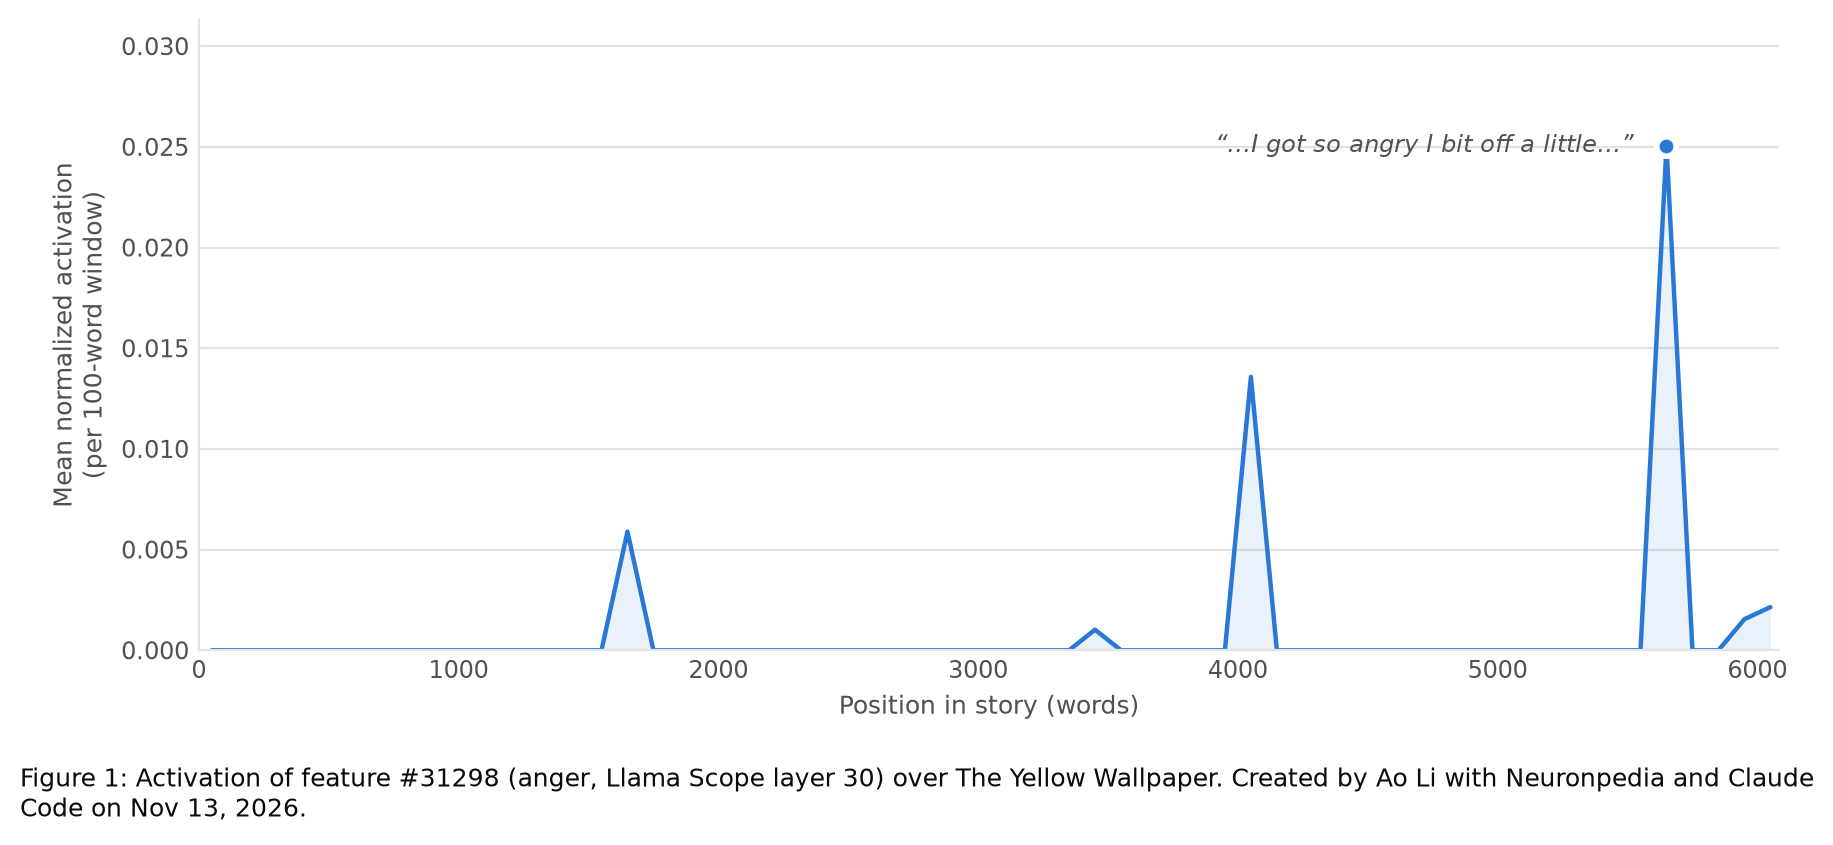

6085 words, 61 windows; firing in 6 of them
  words 5600-5700: 0.0250
  words 4000-4100: 0.0136
  words 1600-1700: 0.0059
  words 6000-6085: 0.0021
  words 5900-6000: 0.0015


In [4]:
import bisect

import matplotlib.pyplot as plt

FIG_SOURCE, FIG_INDEX, FIG_EMOTION = "30-llamascope-res-32k", 31298, "anger"
STORY_NAME = "The Yellow Wallpaper"
WINDOW_WORDS = 100
CREATED_WITH = "Neuronpedia and Claude Code"
FIG_DATE = "Nov 13, 2026"
FIG_PATH = Path("outputs/figures/pilot1/figure1.png")
ARC_PATH = Path("outputs/arcs/sae_arc.json")  # read by 1c_compare_sae_vs_emolex.ipynb

# Colours: one series, so one hue; text and axes stay neutral.
LINE, INK, MUTED, RULE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"


def feature_arc(text: str, source: str, index: int, window_words: int = WINDOW_WORDS):
    """Mean normalized activation of one feature in consecutive windows of `window_words` words.

    Returns (window midpoints in words, window means, words of the text, per-token (word index, value)).
    """
    chunks = _chunks(text)
    with _quiet(), ThreadPoolExecutor(MAX_CONCURRENT) as pool:
        results = list(pool.map(lambda c: _request(source, index, c[0]), chunks))
    max_act = feature_info(source, index)["max_act"]

    body = text.strip()
    word_spans = [m.span() for m in re.finditer(r"\S+", body)]
    word_starts = [s for s, _ in word_spans]
    words = [body[s:e] for s, e in word_spans]

    # Walk the tokens in order (each chunk's tokens, then the whitespace that followed it) to find
    # which word every token belongs to.
    per_token, pos = [], 0
    for (tokens, values), (_, sep) in zip(results, chunks):
        for token, value in zip(tokens, values):
            start = pos + len(token) - len(token.lstrip())
            per_token.append((max(0, bisect.bisect_right(word_starts, start) - 1), min(value / max_act, 1.0)))
            pos += len(token)
        pos += len(sep)
    assert pos == len(body), "tokens don't line up with the text"

    n_windows = -(-len(words) // window_words)
    sums, counts = [0.0] * n_windows, [0] * n_windows
    for word, value in per_token:
        sums[word // window_words] += value
        counts[word // window_words] += 1
    means = [s / c if c else 0.0 for s, c in zip(sums, counts)]
    mids = [min(w * window_words + window_words / 2, len(words)) for w in range(n_windows)]
    return mids, means, words, per_token


mids, means, words, per_token = feature_arc(story, FIG_SOURCE, FIG_INDEX)
ARC_PATH.parent.mkdir(parents=True, exist_ok=True)
ARC_PATH.write_text(json.dumps({
    "method": "sae", "label": f"SAE feature #{FIG_INDEX} (layer {FIG_SOURCE.split('-')[0]})",
    "source": FIG_SOURCE, "index": FIG_INDEX, "emotion": FIG_EMOTION, "story": STORY_NAME,
    "window_words": WINDOW_WORDS, "n_words": len(words), "mids": mids, "values": means,
}, indent=1))

fig, ax = plt.subplots(figsize=(9, 3.8), dpi=200)
ax.fill_between(mids, means, color=LINE, alpha=0.10, linewidth=0)
ax.plot(mids, means, color=LINE, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")

# Mark the highest window with a quote around its strongest token.
peak = max(range(len(means)), key=means.__getitem__)
if means[peak] > 0:
    in_peak = [(v, w) for w, v in per_token if w // WINDOW_WORDS == peak]
    _, peak_word = max(in_peak)
    quote = " ".join(words[max(0, peak_word - 4) : peak_word + 5])
    ax.plot(mids[peak], means[peak], "o", markersize=7, color=LINE, markeredgecolor="white", markeredgewidth=2, zorder=3)
    ax.annotate(
        f"“…{quote}…”", (mids[peak], means[peak]), xytext=(-12, 0), textcoords="offset points",
        ha="right", va="center", fontsize=8.5, color=MUTED, style="italic",
    )

ax.set_xlim(0, len(words))
ax.set_ylim(0, max(means) * 1.25 if max(means) > 0 else 1)
ax.set_xlabel("Position in story (words)", color=MUTED, fontsize=9)
ax.set_ylabel(f"Mean normalized activation\n(per {WINDOW_WORDS}-word window)", color=MUTED, fontsize=9)
ax.grid(axis="y", color=RULE, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(RULE)
ax.tick_params(colors=MUTED, labelsize=8.5, length=0)

layer = FIG_SOURCE.split("-")[0]
caption = (
    f"Figure 1: Activation of feature #{FIG_INDEX} ({FIG_EMOTION}, Llama Scope layer {layer}) over {STORY_NAME}. "
    f"Created by Ao Li with {CREATED_WITH} on {FIG_DATE}."
)
fig.text(0.0, -0.02, caption, ha="left", va="top", fontsize=9, color=INK, wrap=True)
fig.tight_layout()

FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_PATH, bbox_inches="tight", facecolor="white")
plt.show()

top = sorted(range(len(means)), key=means.__getitem__, reverse=True)[:5]
print(f"{len(words)} words, {len(means)} windows; firing in {sum(m > 0 for m in means)} of them")
for w in top:
    print(f"  words {w * WINDOW_WORDS}-{min((w + 1) * WINDOW_WORDS, len(words))}: {means[w]:.4f}")